# CMSE 202 Group Project

## Imports

In [1]:
# data processing
import numpy as np
import pandas as pd

# plotting
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import seaborn as sns

# graphs
import networkx as nx

# machine learning
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.datasets import make_classification
from sklearn.pipeline import Pipeline

# image processing
from PIL import Image
from IPython.display import HTML

## Reading Data

In [2]:
# 2014 tennis matches dataset
atp14 = pd.read_csv("https://raw.githubusercontent.com/JeffSackmann/tennis_atp/refs/heads/master/atp_matches_qual_chall_2014.csv")
# 2024 tennis matches dataset
atp24 = pd.read_csv("https://raw.githubusercontent.com/JeffSackmann/tennis_atp/refs/heads/master/atp_matches_qual_chall_2024.csv")

# check to make sure the two dataframes have the same format
assert(all(atp14.columns == atp24.columns) and all(atp14.dtypes == atp24.dtypes))

# combine rows of both dataframes into one dataframe
atp = pd.concat([atp14, atp24], ignore_index = True)

# convert to lower case
atp = atp.rename(columns = {col_name: col_name.lower() for col_name in atp.columns})

# drop unnecessary columns 
atp = atp.drop(columns = [
    "tourney_id", "draw_size", "tourney_level", "tourney_date", "match_num", "score", "best_of", "round",
    "winner_id", "winner_seed", "winner_entry", "winner_name", "winner_ioc", "winner_rank", "winner_rank_points", "w_svgms", 
    "loser_id", "loser_seed", "loser_entry", "loser_name", "loser_ioc", "loser_rank", "loser_rank_points", "l_svgms"
])

# narrow data down to majors
majors = ["Australian Open", "Roland Garros", "Wimbledon", "US Open"]
atp = atp[atp["tourney_name"].isin(majors)]

pd.set_option('future.no_silent_downcasting', True)
atp['surface'] = atp['surface'].replace({'Grass': 0.0, 'Clay': 1.0, 'Hard': 2.0})

atp.head()

,tourney_name,surface,winner_hand,winner_ht,winner_age,loser_hand,loser_ht,loser_age,minutes,w_ace,...,w_bpsaved,w_bpfaced,l_ace,l_df,l_svpt,l_1stin,l_1stwon,l_2ndwon,l_bpsaved,l_bpfaced
2791,Roland Garros,1.0,R,183.0,32.4,R,180.0,23.6,56.0,4.0,...,1.0,1.0,1.0,2.0,46.0,26.0,13.0,6.0,5.0,10.0
2792,Roland Garros,1.0,R,170.0,23.6,R,188.0,27.6,53.0,8.0,...,1.0,1.0,1.0,1.0,63.0,39.0,21.0,8.0,6.0,11.0
2793,Roland Garros,1.0,R,188.0,20.3,R,175.0,23.1,77.0,0.0,...,3.0,4.0,0.0,1.0,56.0,40.0,17.0,9.0,2.0,7.0
2794,Roland Garros,1.0,R,173.0,30.8,R,191.0,21.3,71.0,3.0,...,0.0,1.0,1.0,4.0,54.0,31.0,19.0,9.0,4.0,8.0
2795,Roland Garros,1.0,R,188.0,28.1,R,188.0,23.8,70.0,2.0,...,2.0,3.0,2.0,2.0,55.0,37.0,18.0,7.0,3.0,8.0


## Creating Difference Features

In [3]:
atp['ace_diff'] = atp['w_ace'] - atp['l_ace']
atp['df_diff'] = atp['w_df'] - atp['l_df']
atp['svpt_diff'] = atp['w_svpt'] - atp['l_svpt']

atp['first_in_diff'] = atp['w_1stin'] - atp['l_1stin']
atp['first_won_diff'] = atp['w_1stwon'] - atp['l_1stwon']
atp['second_won_diff'] = atp['w_2ndwon'] - atp['l_2ndwon']

atp['bp_saved_diff'] = atp['w_bpsaved'] - atp['l_bpsaved']
atp['bp_faced_diff'] = atp['w_bpfaced'] - atp['l_bpfaced']

atp['age_diff'] = atp['winner_age'] - atp['loser_age']
atp['height_diff'] = atp['winner_ht'] - atp['loser_ht']

atp['w_1st_win_pct'] = np.where(
    atp['w_1stin'] > 0,
    atp['w_1stwon'] / atp['w_1stin'],
    np.nan
)

atp['l_1st_win_pct'] = np.where(
    atp['l_1stin'] > 0,
    atp['l_1stwon'] / atp['l_1stin'],
    np.nan
)

atp['w_2nd_win_pct'] = np.where(
    (atp['w_svpt'] - atp['w_1stin']) > 0,
    atp['w_2ndwon'] / (atp['w_svpt'] - atp['w_1stin']),
    np.nan
)

atp['l_2nd_win_pct'] = np.where(
    (atp['l_svpt'] - atp['l_1stin']) > 0,
    atp['l_2ndwon'] / (atp['l_svpt'] - atp['l_1stin']),
    np.nan
)

atp['first_win_pct_diff'] = atp['w_1st_win_pct'] - atp['l_1st_win_pct']
atp['second_win_pct_diff'] = atp['w_2nd_win_pct'] - atp['l_2nd_win_pct']

atp.head()

,tourney_name,surface,winner_hand,winner_ht,winner_age,loser_hand,loser_ht,loser_age,minutes,w_ace,...,bp_saved_diff,bp_faced_diff,age_diff,height_diff,w_1st_win_pct,l_1st_win_pct,w_2nd_win_pct,l_2nd_win_pct,first_win_pct_diff,second_win_pct_diff
2791,Roland Garros,1.0,R,183.0,32.4,R,180.0,23.6,56.0,4.0,...,-4.0,-9.0,8.8,3.0,0.769231,0.500000,0.600000,0.300000,0.269231,0.300000
2792,Roland Garros,1.0,R,170.0,23.6,R,188.0,27.6,53.0,8.0,...,-5.0,-10.0,-4.0,-18.0,0.838710,0.538462,0.400000,0.333333,0.300248,0.066667
2793,Roland Garros,1.0,R,188.0,20.3,R,175.0,23.1,77.0,0.0,...,1.0,-3.0,-2.8,13.0,0.781250,0.425000,0.473684,0.562500,0.356250,-0.088816
2794,Roland Garros,1.0,R,173.0,30.8,R,191.0,21.3,71.0,3.0,...,-4.0,-7.0,9.5,-18.0,0.863636,0.612903,0.714286,0.391304,0.250733,0.322981
2795,Roland Garros,1.0,R,188.0,28.1,R,188.0,23.8,70.0,2.0,...,-1.0,-5.0,4.3,0.0,0.774194,0.486486,0.611111,0.388889,0.287707,0.222222


In [4]:
print("Avg. first won difference: ", atp['first_won_diff'].mean())
print("Avg. second won difference: ", atp['second_won_diff'].mean())
print("Avg. double fault differnce: ", atp['df_diff'].mean())
print("Avg. break point difference", atp['bp_saved_diff'].mean())
print("Avg. ace difference: ", atp['ace_diff'].mean())
print("Avg. height difference: ", atp['height_diff'].mean())
print("Avg. age difference: ", atp['age_diff'].mean())

Avg. first won difference:  3.955290611028316
Avg. second won difference:  1.6214605067064083
Avg. double fault differnce:  -0.7988077496274217
Avg. break point difference -1.1341281669150522
Avg. ace difference:  1.4008941877794336
Avg. height difference:  0.29172320217096337
Avg. age difference:  0.0028097062579820692


## Plotting Difference Features

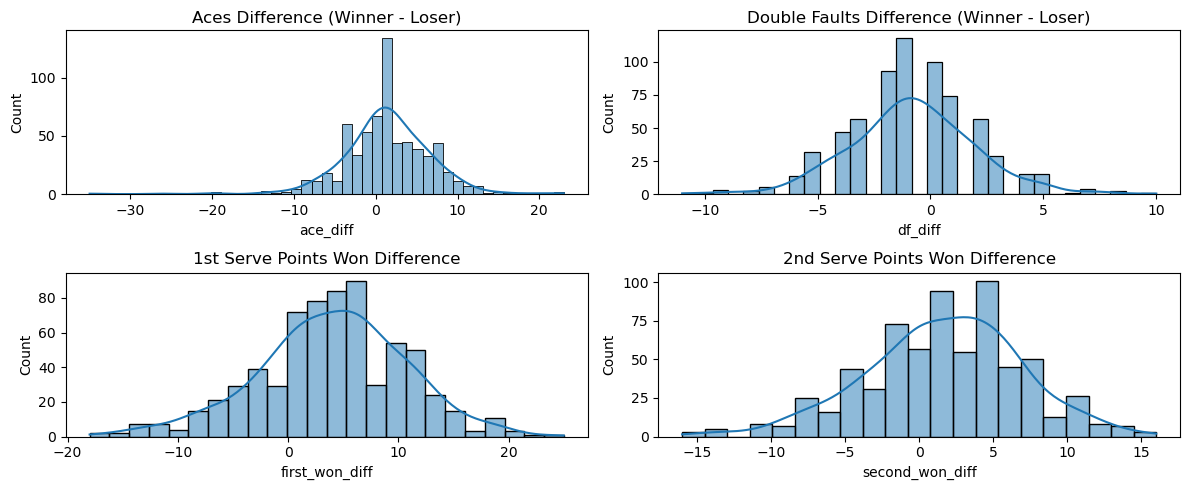

In [5]:
fig, axes = plt.subplots(2, 2, figsize = (12, 5))

sns.histplot(atp['ace_diff'], kde = True, ax = axes[0, 0])
axes[0, 0].set_title("Aces Difference (Winner - Loser)")

sns.histplot(atp['df_diff'], kde = True, ax = axes[0, 1])
axes[0, 1].set_title("Double Faults Difference (Winner - Loser)")

sns.histplot(atp['first_won_diff'], kde = True, ax = axes[1, 0])
axes[1, 0].set_title("1st Serve Points Won Difference")

sns.histplot(atp['second_won_diff'], kde = True, ax = axes[1, 1])
axes[1, 1].set_title("2nd Serve Points Won Difference")

plt.tight_layout()
plt.show()

In [6]:
# rename this column
atp['dominance'] = atp['svpt_diff']

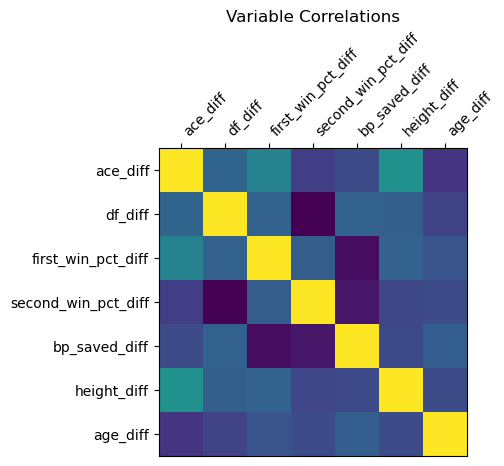

In [7]:
# visualize correlations between variables

corr_cols = [
    'ace_diff', 'df_diff',
    'first_win_pct_diff', 'second_win_pct_diff',
    'bp_saved_diff', 'height_diff', 'age_diff'
]

corr = atp[corr_cols].corr(numeric_only = True)

fig, ax = plt.subplots(figsize = (4, 4))

ax.imshow(corr)
ax.set_xticks(ticks = np.arange(0, len(corr_cols)), labels = corr_cols, rotation = 45, ha = 'left')
ax.xaxis.tick_top()
ax.set_yticks(ticks = np.arange(0, len(corr_cols)), labels = corr_cols)
ax.set_title('Variable Correlations')
plt.show()

## Model

In [8]:
winner = atp.copy()
winner['label'] = 1

loser = atp.copy()
loser['label'] = -1

diff_cols = [
    'ace_diff', 'df_diff',
    'first_win_pct_diff', 'second_win_pct_diff',
    'bp_saved_diff'
]

for col in diff_cols:
    loser[col] = -loser[col]

# combine the two sets of samples into one
samples = pd.concat([winner, loser], ignore_index = True)

features = [
    'ace_diff', 'df_diff',
    'first_win_pct_diff', 'second_win_pct_diff',
    'bp_saved_diff', 'height_diff', 'age_diff'
]

samples = samples.dropna(subset = features)

X = samples[features]
y = samples['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size = 0.2, 
    random_state = 42
)

# this is the main model
pipeline = Pipeline([
    ('feature_standardization', StandardScaler()),
    ('svm', SVC()),
])

# all combinations of these hyperparameters will be tried
parameter_grid = {
    'svm__C': [1, 1.05, 1.075, 1.1, 1.125, 1.15, 1.2],
    'svm__gamma': ['scale', 'auto'],
    'svm__kernel': ['rbf']
}

# this grid search will try various hyperparameter combinations on the main model
grid = GridSearchCV(pipeline, param_grid = parameter_grid)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_
best_hyperparameters = grid.best_params_

y_pred = best_model.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print(f'Best model hyperparameters: {best_hyperparameters}')
print(f'Best model accuracy: {acc:.2%}')

Best model hyperparameters: {'svm__C': 1.1, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Best model accuracy: 88.63%


## End

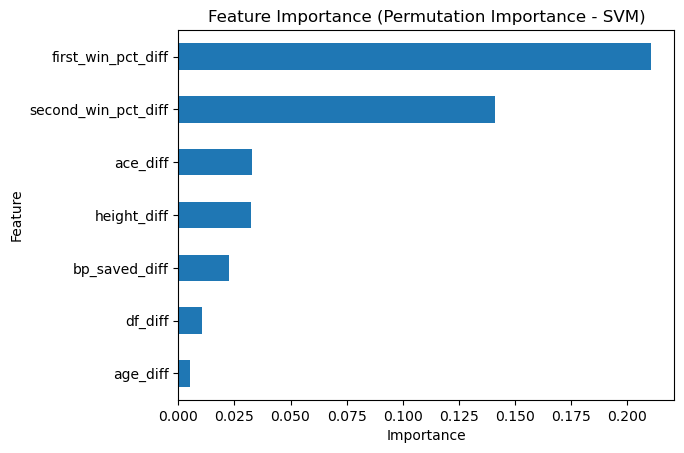

In [9]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

r = permutation_importance(best_model, X_test, y_test, n_repeats=10, random_state=42)

importance = pd.Series(r.importances_mean, index=features)
importance = importance.sort_values()

plt.figure()
importance.plot(kind='barh')
plt.title("Feature Importance (Permutation Importance - SVM)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

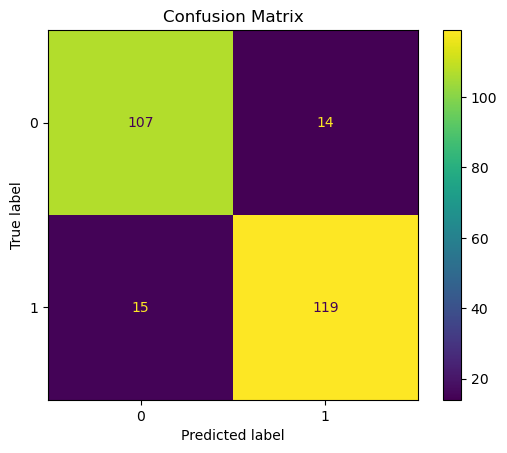

In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

disp.plot()
plt.title("Confusion Matrix")
plt.show()